In [1]:
import os
import sys
from pathlib import Path
import shutil
import zarr
import dask.array as da
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile
from IPython.display import display
import anndata as ad
import pandas as pd
import scanpy as sc
from tqdm import tqdm
import argparse
from loguru import logger

In [2]:
def flatten_list(nested_list):
    """Flatten a nested list."""
    return [item for sublist in nested_list for item in sublist]

In [3]:
def subset_markers(adata, marker_dict):
    markers = list(dict.fromkeys(m for ms in marker_dict.values() for m in ms))
    markers_present = [m for m in markers if m in adata.var_names]
    missing = set(markers) - set(markers_present)
    if missing:
        logger.warning(f"Markers not found in adata and will be skipped: {missing}")
    return adata[:, markers_present].copy()

def preprocess(adata):
    adata.X[np.isnan(adata.X)] = 0
    adata.layers["raw"] = adata.X.copy()
    sc.pp.scale(adata)
    sc.tl.pca(adata, svd_solver='arpack')
    sc.external.pp.bbknn(adata, batch_key="sample",trim=30)

def leiden(adata):
    sc.tl.leiden(adata)

def umap(adata):
    sc.tl.umap(adata)

In [4]:
args = argparse.Namespace()
args.input_anndata_fp = "/mnt/radonc-li02/public/he_codex/raw/tma2025_2/raw_scan/project/external_data/CODEX_TA-418_cores_matched/clustering/TA-417_TA-418.h5ad"
args.output_dir = "/mnt/radonc-li02/public/he_codex/raw/tma2025_2/raw_scan/project/external_data/CODEX_TA-418_cores_matched/clustering/TA-417_TA-418"
args.override = False

In [6]:
output_dir = Path(args.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)
resume = not args.override

fp_preprocessed = output_dir / "01_preprocessed.h5ad"
fp_leiden       = output_dir / "02_leiden.h5ad"
fp_umap         = output_dir / "03_umap.h5ad"
fp_annotated     = output_dir / "05_annotated.h5ad"


adata_preprocessed, adata_leiden, adata_umap = None, None, None
    

In [9]:
adata_raw = ad.read_h5ad(args.input_anndata_fp)

In [10]:
CELL_TYPE_MARKERS_TMA2025 = {
    "Epi":["Pan-CK","E-cadherin","EPCAM"],
    "TCD8":["CD3e","CD8","Granzyme B"],
    "TCD4":["CD3e","CD4"],
    "Treg":["CD3e","FOXP3"],
    "NK":["Granzyme B"],
    "Neutrophil":["MPO","CD66b"],
    "CAF":["FAP"],
    "SMC":["ASMA"],
    "B cell":["CD20"],
    "Plasma":["CD138"],
    "EC":["CD31","CD34"],
    "Mono":["CD14"],
    "M1":["CD68"],
    "M2":["CD163"],
    "DC":["CD11c","HLA-DR"]
}

In [11]:
# step 1: loading and preprocessing
adata_raw = ad.read_h5ad(args.input_anndata_fp)
adata = adata_raw
adata = subset_markers(adata, CELL_TYPE_MARKERS_TMA2025)
preprocess(adata)
adata_preprocessed = adata

/mnt/radonc-li02/private/lzx325/env/scimap2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
# save step 1 result
if True:
    adata_preprocessed.write_h5ad(fp_preprocessed)
    logger.info(f"Saved preprocessed anndata to {fp_preprocessed}")

2026-07-24 12:52:13.533 | INFO     | __main__:<module>:4 - Saved preprocessed anndata to /mnt/radonc-li02/public/he_codex/raw/tma2025_2/raw_scan/project/external_data/CODEX_TA-418_cores_matched/clustering/TA-417_TA-418/01_preprocessed.h5ad


In [ ]:
# step 2: Leiden clustering
if True:
    adata_preprocessed = ad.read_h5ad(fp_preprocessed)
adata = adata_preprocessed
leiden(adata)
adata_leiden = adata


/tmp/ipykernel_1139281/2470414817.py:17: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata)


In [ ]:
# save step 2 result
if True:
    adata_leiden.write_h5ad(fp_leiden)
    logger.info(f"Saved Leiden anndata to {fp_leiden}")

In [ ]:
# step 3: UMAP
if True:
    adata_leiden = ad.read_h5ad(fp_leiden)
adata = adata_leiden
umap(adata)
adata_umap = adata

In [ ]:
# save step 3 result
if True:
    adata_umap.write_h5ad(fp_umap)
    logger.info(f"Saved UMAP anndata to {fp_umap}")

In [7]:
# step 4: visualization
if True:
    adata_umap = ad.read_h5ad(fp_umap)

In [189]:
# for TA-124
fp_annotation_csv = Path(output_dir)/"cell_annotations.csv"
fp_annotation = pd.read_csv(fp_annotation_csv,index_col=0)
assert (adata_umap.obs.index == fp_annotation.index).all()
adata_umap.obs["leiden"] = fp_annotation["original_clusters"].astype(str)

In [66]:
marker_means = (
    pd.DataFrame(adata_umap.layers["raw"], index=adata_umap.obs_names, columns=adata_umap.var_names)
    .assign(leiden=adata_umap.obs["leiden"].values)
    .groupby("leiden")
    .mean()
)

CELL_TYPE_MARKERS_TMA2025 = {
    "Epi":["Pan-CK","E-cadherin","EPCAM"],
    "TCD8":["CD3e","CD8","Granzyme B"],
    "TCD4":["CD3e","CD4"],
    "Treg":["CD3e","FOXP3"],
    "NK":["Granzyme B"],
    "Neutrophil":["MPO","CD66b"],
    "CAF":["FAP"],
    "SMC":["ASMA"],
    "B cell":["CD20"],
    "Plasma":["CD138"],
    "EC":["CD31","CD34"],
    "Mono":["CD14"],
    "M1":["CD68"],
    "M2":["CD163"],
    "DC":["CD11c","HLA-DR"]
}

exclude_clusters = [
    '31',
    "32",
    "33",
    "34",
    "35",
    "36",
    "37",
    "38",
    "39",
    "40",
    "41",
    "42",
    "43",
    "44",
    "45",
    "46",
    "47",
    "48",
    "49",
    "50",
    "51",
    "52",
]

plot_marker_list = [item  for v in CELL_TYPE_MARKERS_TMA2025.values() for item in v]

/tmp/ipykernel_1381693/3948528860.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("leiden")


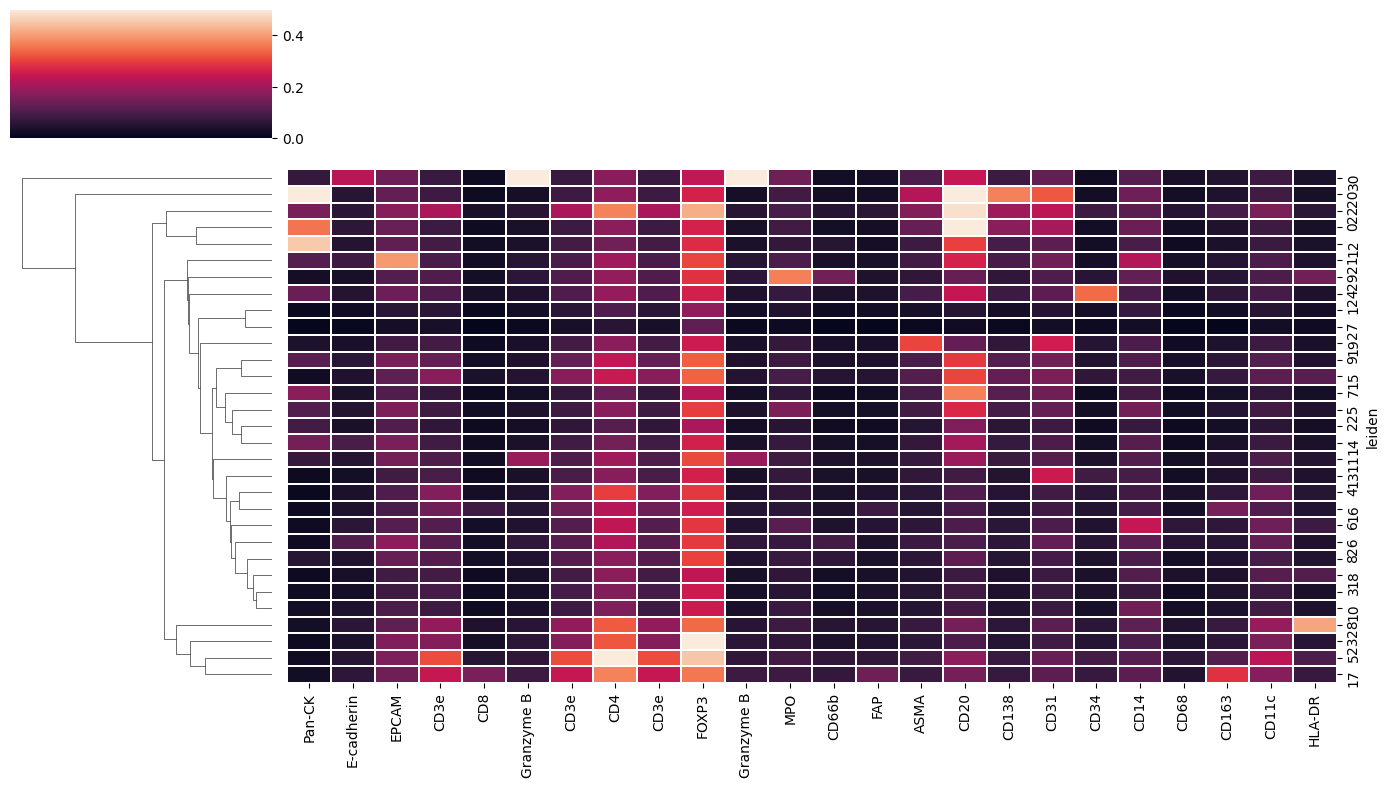

In [67]:
n_clusters, n_markers = marker_means.shape
plot_data = marker_means.loc[~marker_means.index.isin(exclude_clusters), plot_marker_list]
# zscore_data = (zscore_data - zscore_data.values.mean(axis = 0, keepdims=True))/(zscore_data.values.std(axis=0, keepdims=True))
sns.clustermap(plot_data, linewidths=0.3, xticklabels = 1, yticklabels = 1, col_cluster=False, row_cluster = True,vmin=0,vmax=0.5, z_score=None)
plt.gcf().set_size_inches((14,8))
plt.tight_layout()

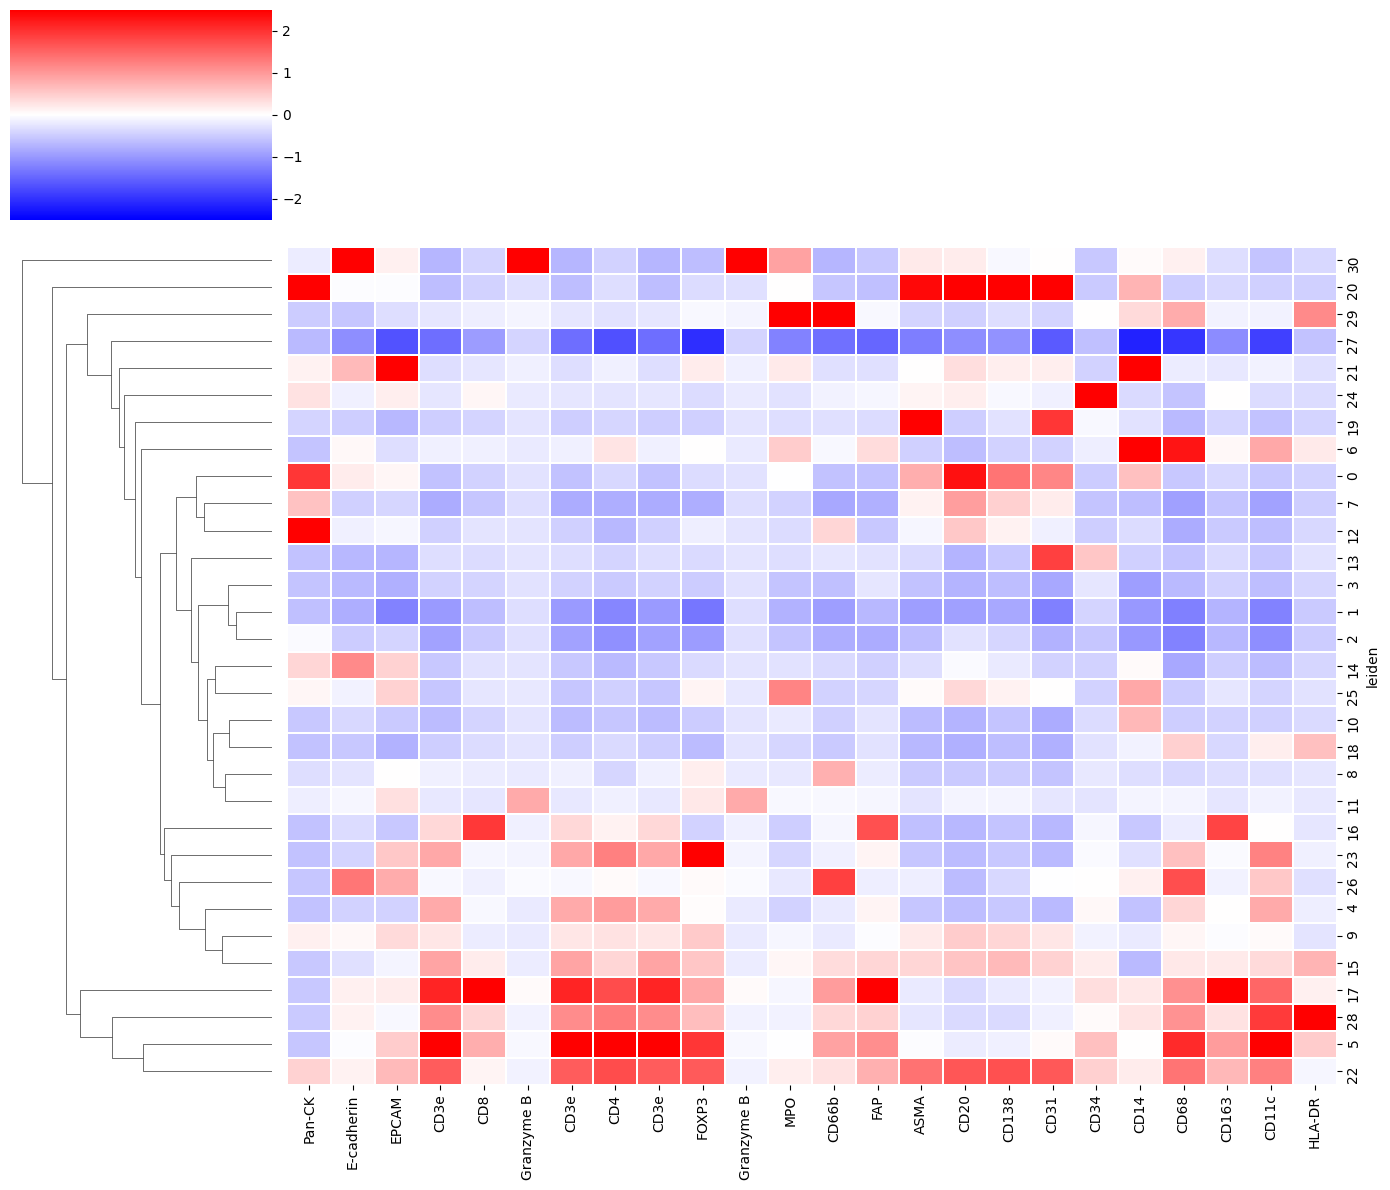

In [68]:
n_clusters, n_markers = marker_means.shape
plot_data = marker_means

# for TA-124
# plot_data = marker_means.loc[~marker_means.index.isin(exclude_clusters),plot_marker_list]

# for TA-125
# plot_data = marker_means.loc[~marker_means.index.isin(exclude_clusters),plot_marker_list]

# for TA-150
plot_data = marker_means.loc[~marker_means.index.isin(exclude_clusters),plot_marker_list]

sns.clustermap(plot_data, linewidths=0.3, xticklabels = 1, yticklabels = 1, col_cluster=False, row_cluster = True, z_score=1, cmap='bwr', vmin=-2.5, vmax=2.5)
plt.gcf().set_size_inches((14,12))
plt.tight_layout()

In [78]:
# step 5: cluster annotation
if True:
    adata_umap = ad.read_h5ad(fp_umap)
    
adata = adata_umap
cluster_annotation_fp = "/mnt/radonc-li02/public/he_codex/raw/tma2025_2/raw_scan/project/external_data/CODEX_TA-418_cores_matched/clustering/TA-417_TA-418/cluster_annotation_v1.csv"
merged_cluster_annotation_fp = "/mnt/radonc-li02/public/he_codex/raw/tma2025_2/raw_scan/project/external_data/CODEX_TA-418_cores_matched/clustering/TA-417_TA-418/merged_cluster_annotation_v1.csv"

# load annotations
cluster_annotation = pd.read_csv(cluster_annotation_fp, dtype = {"original_clusters":"category"})
merged_cluster_annotation = pd.read_csv(merged_cluster_annotation_fp, dtype={"merged_clusters":"category"})
merged_cluster_annotation = merged_cluster_annotation[merged_cluster_annotation["merged_clusters"].isin(cluster_annotation["merged_clusters"])]
# make merged_cluster categorical with levels ordered as in merged_cluster_annotation
merged_levels = merged_cluster_annotation["merged_clusters"].astype(str).tolist()
merged_cluster_annotation["merged_clusters"] = pd.Categorical(
    merged_cluster_annotation["merged_clusters"],
    categories=merged_levels,
    ordered=True
)

# merge annotation tables on merged_cluster
cluster_annotation_full = cluster_annotation.merge(
    merged_cluster_annotation,
    on="merged_clusters",
    how="left",
    validate="many_to_one",
)

# ensure merged_cluster is categorical in merged frame as well
cluster_annotation_full["merged_clusters"] = pd.Categorical(
    cluster_annotation_full["merged_clusters"],
    categories=merged_levels,
    ordered=True,
)

# append merged annotation columns to adata.obs using original_cluster key
new_obs = pd.merge(
    adata.obs,
    cluster_annotation_full,
    left_on="leiden",
    right_on = "original_clusters",
    how="left"
)

new_obs.index = adata.obs.index
adata.obs = new_obs
adata_annotated = adata
if True:
    fp_annotated     = output_dir / "05_annotated_v1.h5ad"
    adata_annotated.write_h5ad(fp_annotated)

In [79]:
# step 6: visualization with annotated clusters
if False:
    fp_annotated     = output_dir/ "05_annotated_v1.h5ad"
    adata_annotated = ad.read_h5ad(fp_annotated)
    
adata = adata_annotated
marker_means = (
    pd.DataFrame(adata.layers["raw"], index=adata.obs_names, columns=adata.var_names)
    .assign(merged_clusters=adata.obs["merged_clusters"].values)
    .groupby("merged_clusters")
    .mean()
)

/tmp/ipykernel_1381693/3910629427.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("merged_clusters")


In [101]:
adata.obs["merged_clusters"].value_counts()

merged_clusters
Epi          582640
TCD4         330442
EpiT         299054
undefined    286601
Endo         107671
Macro        101856
Mono          87472
Fibro         66052
DC            64689
TCD8          57773
Neutro        53288
Myofibro      36934
Name: count, dtype: int64

In [21]:
if False:
    fp_annotation_csv = Path(output_dir)/"cell_annotations.csv"
    adata_annotated.obs = adata_annotated.obs.rename({"sample":"sample_name"},axis=1)
    adata_annotated.obs.index.name = "CellID"
    adata_annotated.obs.to_csv(fp_annotation_csv)

In [80]:
CELL_TYPE_MARKERS_TMA2025 = {
    "Epi":["Pan-CK","E-cadherin","EPCAM"],
    "TCD8":["CD3e","CD8","Granzyme B"],
    "TCD4":["CD3e","CD4"],
    "Treg":["CD3e","FOXP3"],
    "NK":["Granzyme B"],
    "Neutro":["MPO","CD66b"],
    "Fibro":["FAP"],
    "Myofibro":["ASMA"],
    "B":["CD20"],
    "Plasma":["CD138"],
    "Endo":["CD31","CD34"],
    "Mono":["CD14"],
    "Macro":["CD68","CD163"],
    "DC":["CD11c","HLA-DR"]
}

marker_list = [item  for v in CELL_TYPE_MARKERS_TMA2025.values() for item in v]

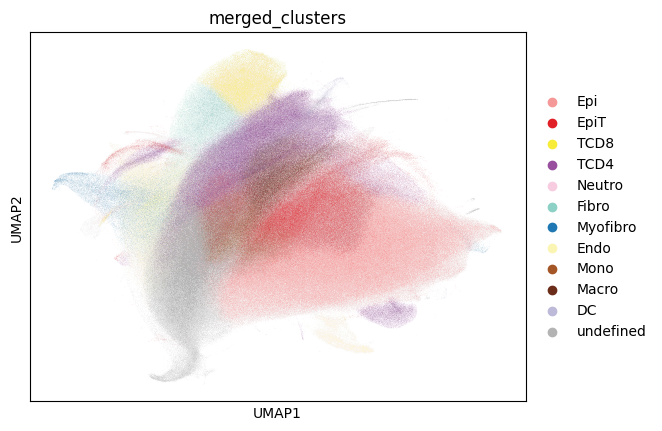

In [97]:
palette = dict(zip(adata_annotated.obs["merged_clusters"],adata_annotated.obs["color"]))
sc.pl.umap(adata_annotated,color="merged_clusters", palette = palette)

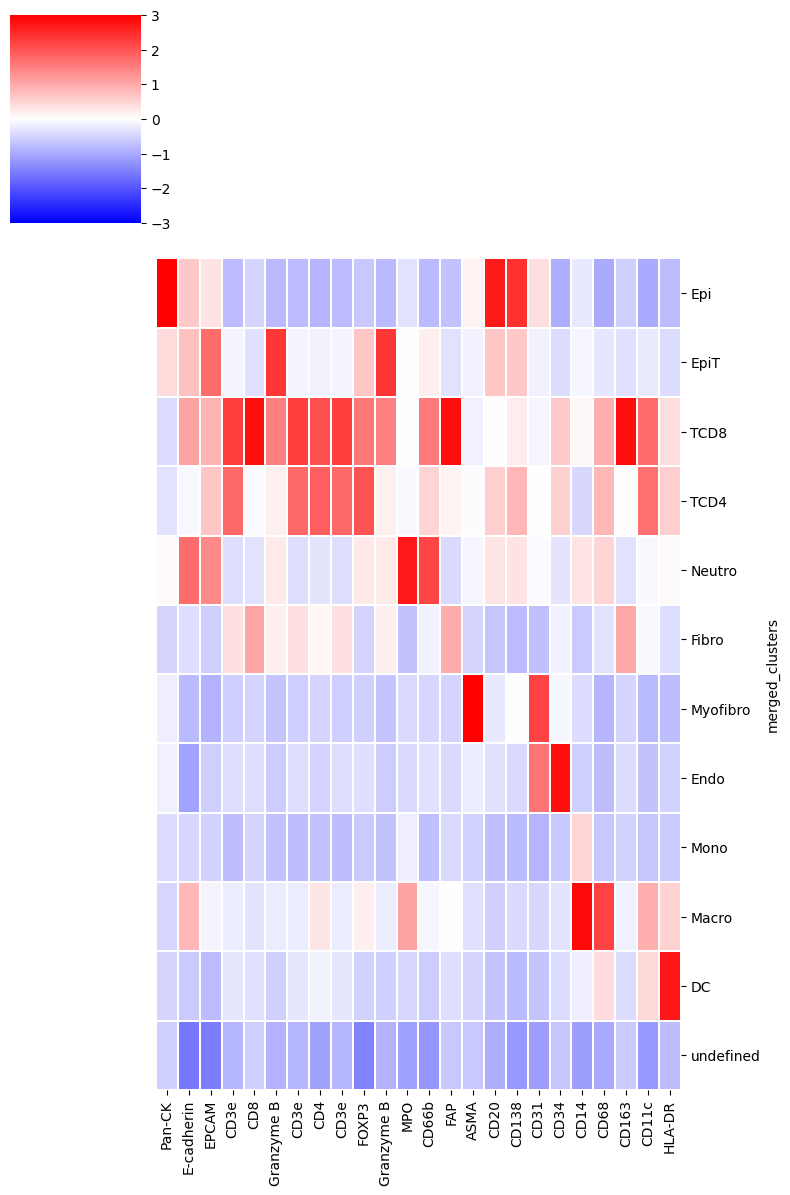

In [99]:
n_clusters, n_markers = marker_means.shape
plot_data = marker_means.loc[:,marker_list]
sns.clustermap(plot_data, linewidths=0.3, xticklabels = 1, yticklabels = 1, col_cluster=False, row_cluster = False, z_score=1, cmap='bwr', vmin=-3, vmax=3)
fig, ax = plt.gcf(),plt.gca()
fig.set_size_inches((8,12))
plt.tight_layout()